# 01. EV Growth Analysis (2019–2025)

## What This Notebook Does
This notebook looks at how EV ownership grew in New Jersey counties between 2019 and 2025. 

## Steps
1. **Load Data**: Bring in EV registration files for 2019, 2022, and 2025.
2. **Calculate Growth**: See which counties added the most EVs over time.
3. **Save Results**: Export the clean dataset to `data/processed/` for the next steps.

---

## Step 1: Load the Excel Files

### What we are doing:
We load the state vehicle registration spreadsheets for three key years:
* `afvreport201912.xlsx` (December 2019 baseline)
* `afvreport202212.xlsx` (December 2022 mid-point)
* `afvreport202512.xlsx` (December 2025 latest data)

### Why:
Comparing these three years lets us see how fast EV adoption expanded across New Jersey counties over a 6-year period.

In [10]:
import pandas as pd

# Function to automatically find and load the county summary sheet
def load_county_sheet(filepath):
    xl = pd.ExcelFile(filepath)
    # Find the sheet containing 'CntySummary' in its name
    county_sheet = [s for s in xl.sheet_names if 'CntySummary' in s][0]
    return pd.read_excel(filepath, sheet_name=county_sheet)

# Load each dataset
df_2019 = load_county_sheet("../data/raw/afvreport201912.xlsx")
df_2022 = load_county_sheet("../data/raw/afvreport202212.xlsx")
df_2025 = load_county_sheet("../data/raw/afvreport202512.xlsx")

# Check the first few rows of each dataset
print("2019 County Data:")
display(df_2019.head())

print("2022 County Data:")
display(df_2022.head())

print("2025 County Data:")
display(df_2025.head())


2019 County Data:


,County,VehicleClass,Registered Vehicles,NonAFV,NonAFV %,AFVs,ATPZEV,ATPZEV %,NEV,NEV %,PHEV,PHEV %,ZEV,ZEV %,ZEV plus PHEV,ZEV plus PHEV %,NG,NG %,FC,FC%
0,Atlantic,HDT,11210,11008.0,0.981980,202,NaN,0.000000,NaN,0.0,NaN,0.000000,NaN,0.000000,0,0.000000,202.0,0.018020,NaN,0.0
1,Atlantic,LDT,104574,104007.0,0.994578,567,492.0,0.004705,NaN,0.0,17.0,0.000163,40.0,0.000383,57,0.000545,18.0,0.000172,NaN,0.0
2,Atlantic,LDV,83551,81224.0,0.972149,2327,1918.0,0.022956,NaN,0.0,184.0,0.002202,222.0,0.002657,406,0.004859,3.0,0.000036,NaN,0.0
3,Atlantic,LSV,40,NaN,0.000000,40,NaN,0.000000,40.0,1.0,NaN,0.000000,NaN,0.000000,0,0.000000,NaN,0.000000,NaN,0.0
4,Atlantic,MDT,867,840.0,0.968858,27,NaN,0.000000,NaN,0.0,NaN,0.000000,NaN,0.000000,0,0.000000,27.0,0.031142,NaN,0.0


2022 County Data:


,County,VehClass,Vehicles,ICE,NonAFV %,AFVs,AFV %,HEV,HEV %,NEV,NEV %,PHEV,PHEV %,BEV,BEV %,BEV plus PHEV,BEV plus PHEV %,NG,NG %
0,Atlantic,HDT,5485.0,5373.0,0.979581,112.0,0.020419,NaN,0.000000,NaN,0.0,NaN,0.000000,NaN,0.000000,0.0,0.000000,112.0,0.020419
1,Atlantic,LDT,108472.0,106442.0,0.981285,2030.0,0.018715,1367.0,0.012602,NaN,0.0,211.0,0.001945,442.0,0.004075,653.0,0.006020,10.0,0.000092
2,Atlantic,LDV,75285.0,72392.0,0.961573,2893.0,0.038427,2039.0,0.027084,NaN,0.0,265.0,0.003520,586.0,0.007784,851.0,0.011304,3.0,0.000040
3,Atlantic,LSV,108.0,NaN,0.000000,108.0,1.000000,NaN,0.000000,108.0,1.0,NaN,0.000000,NaN,0.000000,0.0,0.000000,NaN,0.000000
4,Atlantic,MDT,9665.0,9604.0,0.993689,61.0,0.006311,NaN,0.000000,NaN,0.0,NaN,0.000000,4.0,0.000414,4.0,0.000414,57.0,0.005898


2025 County Data:


,County,VehClass,Vehicles,ICE,NonAFV %,AFVs,AFV %,HEV,HEV %,NEV,NEV %,PHEV,PHEV %,BEV,BEV %,BEV plus PHEV,BEV plus PHEV %,NG,NG %,Unnamed: 19
0,Atlantic,HDT,5878.0,5708.0,0.971079,170.0,0.028921,NaN,0.000000,NaN,0.00000,NaN,0.000000,1.0,0.000170,1.0,0.000170,169.0,0.028751,NaN
1,Atlantic,LDT,125522.0,119407.0,0.951283,6115.0,0.048717,3449.0,0.027477,NaN,0.00000,810.0,0.006453,1855.0,0.014778,2665.0,0.021231,1.0,0.000008,NaN
2,Atlantic,LDV,69393.0,65509.0,0.944029,3884.0,0.055971,2619.0,0.037742,NaN,0.00000,274.0,0.003949,984.0,0.014180,1258.0,0.018129,7.0,0.000101,NaN
3,Atlantic,LSV,369.0,1.0,0.002710,368.0,0.997290,NaN,0.000000,368.0,0.99729,NaN,0.000000,NaN,0.000000,0.0,0.000000,NaN,0.000000,NaN
4,Atlantic,MDT,10344.0,10153.0,0.981535,191.0,0.018465,NaN,0.000000,NaN,0.00000,NaN,0.000000,153.0,0.014791,153.0,0.014791,38.0,0.003674,NaN


## Step 2: Clean and Merge County EV Totals

### What we are doing:
1. Extract registration counts for plug-in electric vehicles (Battery EVs and Plug-in Hybrids) for each county.
2. Combine the 2019, 2022, and 2025 counts into a single table linked by `County`.
3. Filter out non-county summary rows (like "Totals" or state totals) so they don't mess up our math.

### Why:
Raw state reports include extra summary rows and hybrid vehicle types. We only want pure plug-in vehicles grouped cleanly by individual counties.

### Note on EV Terminology & Classifications
* **BEV (Battery Electric Vehicle):** 100% fully electric vehicles powered entirely by a battery (e.g., Tesla). In older 2019 reports, this was referred to as **ZEV (Zero Emission Vehicle)**.
* **PHEV (Plug-in Hybrid Electric Vehicle):** Vehicles with both an electric battery and a gas engine that require plugging in to charge.
* **HEV / ATPZEV:** Traditional hybrids that **cannot** be plugged in and charge solely via regenerative braking (excluded from our charging demand analysis).
* **Summary:** We combine **BEV + PHEV** (or ZEV + PHEV) because these are the vehicles that physically rely on public charging stations along major highway corridors.

In [11]:
# Function to aggregate total EVs per county
def get_county_ev_totals(df, ev_col_name, year):
    # Fill missing values with 0
    df[ev_col_name] = df[ev_col_name].fillna(0)
    
    # Group by County and sum up the total EVs
    county_df = df.groupby('County')[ev_col_name].sum().reset_index()
    
    # Rename column to a clean standard format
    county_df = county_df.rename(columns={ev_col_name: f'ev_count_{year}'})
    return county_df

# Process all 3 years
ev_2019 = get_county_ev_totals(df_2019, 'ZEV plus PHEV', 2019)
ev_2022 = get_county_ev_totals(df_2022, 'BEV plus PHEV', 2022)
ev_2025 = get_county_ev_totals(df_2025, 'BEV plus PHEV', 2025)

# Merge all three years into one clean table
df_ev_growth = ev_2019.merge(ev_2022, on='County').merge(ev_2025, on='County')

# Display the merged clean table
display(df_ev_growth.head(10))

,County,ev_count_2019,ev_count_2022,ev_count_2025
0,Atlantic,463,1508.0,4078.0
1,Bergen,4732,13190.0,40397.0
2,Burlington,1290,4106.0,11078.0
3,Camden,1511,4240.0,10844.0
4,Cape May,214,642.0,1425.0
5,Cumberland,142,410.0,1112.0
6,Essex,2514,8354.0,20882.0
7,Gloucester,520,1816.0,5112.0
8,Hudson,1165,4581.0,12824.0
9,Hunterdon,688,1708.0,4278.0


## Step 3: Calculate Growth Metrics

### What we are doing:
We compute two growth metrics for every county from 2019 to 2025:
* **Absolute Growth:** $\text{2025 EV Count} - \text{2019 EV Count}$ (how many total new EVs were added).
* **Percentage Growth:** $\left(\frac{\text{2025 EV Count} - \text{2019 EV Count}}{\text{2019 EV Count}}\right) \times 100$ (the percentage increase).

### Why:
Looking at both total numbers and percentage growth shows us both large EV hubs (like Bergen) and fast-emerging growth areas (like Ocean).

In [12]:
import os

# 1. Calculate Absolute and Percentage Growth
df_ev_growth['absolute_growth'] = df_ev_growth['ev_count_2025'] - df_ev_growth['ev_count_2019']
df_ev_growth['pct_growth'] = ((df_ev_growth['ev_count_2025'] - df_ev_growth['ev_count_2019']) / df_ev_growth['ev_count_2019']) * 100

# Convert counts and absolute growth to integers
df_ev_growth['ev_count_2022'] = df_ev_growth['ev_count_2022'].astype(int)
df_ev_growth['ev_count_2025'] = df_ev_growth['ev_count_2025'].astype(int)
df_ev_growth['absolute_growth'] = df_ev_growth['absolute_growth'].astype(int)

# 2. Sort by 2025 total EV volume to identify top counties
df_ranked = df_ev_growth.sort_values(by='ev_count_2025', ascending=False).reset_index(drop=True)

# 3. Ensure the output folder exists and save the cleaned dataset
os.makedirs("../data/processed", exist_ok=True)
df_ranked.to_csv("../data/processed/county_ev_growth_2019_2025.csv", index=False)

# Display Top 10 Counties
print("Top 10 New Jersey Counties by 2025 EV Count:")
display(df_ranked.head(10))

Top 10 New Jersey Counties by 2025 EV Count:


,County,ev_count_2019,ev_count_2022,ev_count_2025,absolute_growth,pct_growth
0,Totals,29960,91515,265547,235587,786.338451
1,Bergen,4732,13190,40397,35665,753.698225
2,Middlesex,3349,10034,32347,28998,865.870409
3,Monmouth,2497,7980,23271,20774,831.958350
4,Essex,2514,8354,20882,18368,730.628481
5,Morris,2364,6792,19166,16802,710.744501
6,Somerset,2172,5635,15761,13589,625.644567
7,Mercer,1985,5322,14039,12054,607.254408
8,Ocean,1012,4576,14038,13026,1287.154150
9,Union,1476,4512,13683,12207,827.032520


## Step 4: Save Data & Chart Top 10 Counties

### What we are doing:
1. Save our cleaned dataset to `../data/processed/county_ev_growth_2019_2025.csv`.
2. Create a bar chart comparing 2019 vs. 2025 EV counts for the top 10 counties.

### Why:
Saving the file lets us use it in Notebook 02. The chart makes it easy to see which counties lead New Jersey in overall EV volume.

Matplotlib is building the font cache; this may take a moment.


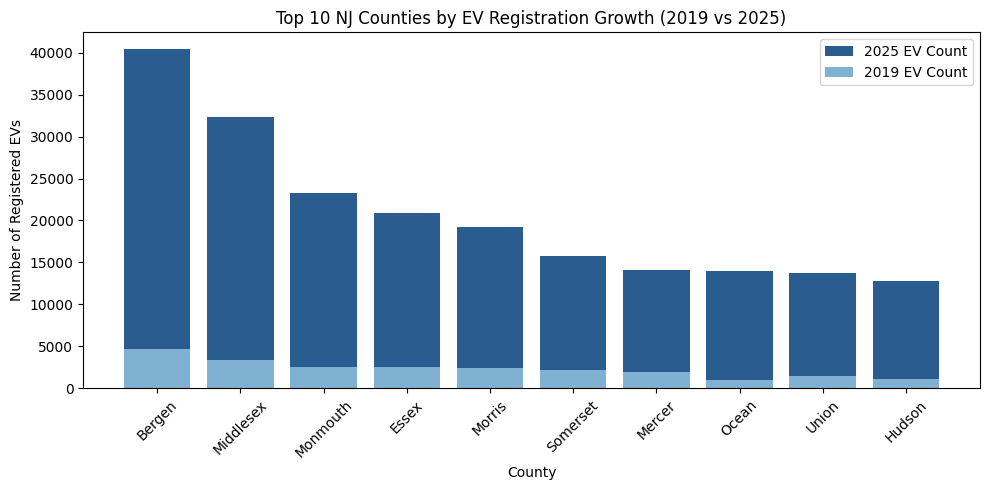

In [19]:
import matplotlib.pyplot as plt

# 1. Filter out 'Totals' row and re-sort
df_counties_only = df_ranked[df_ranked['County'] != 'Totals'].copy()

# Save the county-only cleaned file
df_counties_only.to_csv("../data/processed/county_ev_growth_2019_2025.csv", index=False)

# Get Top 10 counties
top_10 = df_counties_only.head(10)

# 2. Plot 2019 vs 2025 Comparison
plt.figure(figsize=(10, 5))
plt.bar(top_10['County'], top_10['ev_count_2025'], label='2025 EV Count', color='#2b5c8f')
plt.bar(top_10['County'], top_10['ev_count_2019'], label='2019 EV Count', color='#80b1d3')

plt.title('Top 10 NJ Counties by EV Registration Growth (2019 vs 2025)')
plt.xlabel('County')
plt.ylabel('Number of Registered EVs')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

## Key Findings & Summary
* **Top EV Adoption Hubs:** Bergen, Middlesex, Monmouth, and Essex lead New Jersey in overall EV registration volume.
* **Rapid Growth:** EV adoption accelerated dramatically between 2019 and 2025 across all major commuter corridors.
* **Processed Dataset Exported:** The cleaned county-level growth dataset has been saved to `data/processed/county_ev_growth_2019_2025.csv` for use in infrastructure and highway traffic analysis.